# 국내채권마스터(PRBD01N001) EDA

**데이터셋**: `PRBD01N001_국내채권마스터`
**최종 추출일자(스키마 기준)**: 2026-07-11
**목적**: 국내채권 마스터 데이터의 구조, 결측/이상치, 범주형·수치형 분포, 수익률/듀레이션/신용등급 특성을 탐색

## 1. 라이브러리 임포트 및 환경 설정

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

%matplotlib inline


In [2]:
# --- 차트 스타일 (색상 시스템: 고정 순서 카테고리 팔레트) -------------------
# 카테고리형 변수를 그릴 때는 항상 이 순서(CAT_COLORS)를 그대로 사용하고,
# 그룹이 8개를 넘으면 상위 N개 + "기타"로 묶어서 사용합니다.
CAT_COLORS = [
    "#2a78d6",  # 1 blue
    "#eb6834",  # 2 orange
    "#1baf7a",  # 3 aqua
    "#eda100",  # 4 yellow
    "#e87ba4",  # 5 magenta
    "#008300",  # 6 green
    "#4a3aa7",  # 7 violet
    "#e34948",  # 8 red
]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_BLUE_CMAP = sns.blend_palette(SEQ_BLUE, as_cmap=True)
DIVERGING_CMAP = sns.diverging_palette(220, 10, s=75, l=50, sep=10, as_cmap=True)  # blue-gray-red

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRIDLINE,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})


def cat_colors(n: int) -> list:
    '''카테고리 개수만큼 고정 순서 팔레트에서 색을 가져온다. 8개 초과 시 순환하지 않고 반복 사용을 피하려면
    호출 전에 top-N + "기타"로 묶는 것을 권장.'''
    if n <= len(CAT_COLORS):
        return CAT_COLORS[:n]
    reps = (n // len(CAT_COLORS)) + 1
    return (CAT_COLORS * reps)[:n]


## 2. 데이터 로드

`DATA_PATH`만 실제 파일 경로로 바꿔서 사용하세요. csv / parquet / xlsx 로더를 모두 준비해뒀고,
`DATA_PATH`의 확장자에 따라 자동으로 분기합니다.

In [5]:
# TODO: 실제 데이터 경로로 수정
DATA_PATH = Path("../perprocessed_datas/v4/PRBD01N001_국내채권마스터_20260711_datarows.xlsx")

# 스키마 기준 컬럼 순서 (raw 데이터 컬럼명이 다르면 여기만 맞춰서 조정)
SCHEMA_COLUMNS = [
    "PD_NO", "PD_EXG_MKT", "PD_NM", "PD_ABRV_NM", "PD_ENG_NM", "PD_ABRV_ENG_NM",
    "PD_CTRY_CD", "PD_PBCM", "STD_PD_MCLS_NM", "STD_PD_SCLS_NM", "BD_KND", "CURR_CD",
    "ISU_BAL_AMT", "ISU_DT", "MAT_DT", "SRFC_IRT", "PD_EVCO_CRD_GRD", "PD_RISK_GCD",
    "PD_STD_INFO_UPDATE", "BUY_YIELD", "CORP_PRETAX_YIELD", "CORP_AFTER_TAX_YIELD",
    "AFTER_TAX_YIELD", "PREF_TAX_YIELD", "AVG_ANNUAL_TAX_YIELD", "DEPO_EQUIV_YIELD_154",
    "BUYABLE_QUANTITY", "REMAINING_DAYS", "DUR", "COV", "NDY_DUR", "NDY_COV",
    "EVAL_PRICE", "APPLIED_YIELD", "DIRTY", "NDY_EVAL_PRICE", "NDY_APPLIED_YIELD",
    "NDY_DIRTY", "CRD_GRD", "CRD_GRD_DT",
]


def load_bond_master(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in (".parquet", ".pq"):
        return pd.read_parquet(path)
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(path)
    raise ValueError(f"지원하지 않는 확장자입니다: {suffix}")


df_raw = load_bond_master(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols")
df_raw.head()


Loaded: 42,394 rows x 40 cols


,PD_NO,PD_EXG_MKT,PD_NM,PD_ABRV_NM,PD_ENG_NM,PD_ABRV_ENG_NM,PD_CTRY_CD,PD_PBCM,STD_PD_MCLS_NM,STD_PD_SCLS_NM,BD_KND,CURR_CD,ISU_BAL_AMT,ISU_DT,MAT_DT,SRFC_IRT,PD_EVCO_CRD_GRD,PD_RISK_GCD,PD_STD_INFO_UPDATE,BUY_YIELD,CORP_PRETAX_YIELD,CORP_AFTER_TAX_YIELD,AFTER_TAX_YIELD,PREF_TAX_YIELD,AVG_ANNUAL_TAX_YIELD,DEPO_EQUIV_YIELD_154,BUYABLE_QUANTITY,REMAINING_DAYS,DUR,COV,NDY_DUR,NDY_COV,EVAL_PRICE,APPLIED_YIELD,DIRTY,NDY_EVAL_PRICE,NDY_APPLIED_YIELD,NDY_DIRTY,CRD_GRD,CRD_GRD_DT
0,KR101501DA16,장내,국민주택1종채권 20-01,국민주택1종20-01,KOREA NATIONAL HOUSING BOND (Ⅰ)20-01,KNHB (Ⅰ)20-01,KR,대한민국,국공채,국민주택,국민주택1종,KRW,1397549160000,2020-01-31,2025-01-31,1.0000,NaN,6,2025-02-03,3.2000,3.1986,3.0415,3.0415,3.1017,0.0000,3.5952,"27,568,000.0000",0.0000,0.0000,0.0000,0.0000,0.0000,"10,510.0000",2.8340,"10,510.0000",0.0000,0.0000,0.0000,NaN,NaN
1,KR101501DA24,장내,국민주택1종채권 20-02,국민주택1종20-02,KOREA NATIONAL HOUSING BOND (Ⅰ)20-02,KNHB (Ⅰ)20-02,KR,대한민국,국공채,국민주택,국민주택1종,KRW,1621087290000,2020-02-29,2025-02-28,1.0000,NaN,6,2025-03-04,3.2800,3.2808,3.1230,3.1230,3.1834,0.0000,3.6915,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"10,510.0000",2.8210,"10,510.0000",0.0000,0.0000,0.0000,NaN,NaN
2,KR101501DA32,장내,국민주택1종채권 20-03,국민주택1종20-03,KOREA NATIONAL HOUSING BOND (Ⅰ)20-03,KNHB (Ⅰ)20-03,KR,대한민국,국공채,국민주택,국민주택1종,KRW,1559671920000,2020-03-31,2025-03-31,1.0000,NaN,6,2025-04-01,3.3500,3.3524,3.1947,3.1947,3.2551,0.0000,3.7762,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"10,510.0000",2.7030,"10,510.0000",0.0000,0.0000,0.0000,NaN,NaN
3,KR101501DA40,장내,국민주택1종채권 20-04,국민주택1종20-04,KOREA NATIONAL HOUSING BOND (Ⅰ)20-04,KNHB (Ⅰ)20-04,KR,대한민국,국공채,국민주택,국민주택1종,KRW,1387802630000,2020-04-30,2025-04-30,1.0000,NaN,6,2025-05-02,3.3500,3.3669,3.2082,3.2082,3.2690,0.0000,3.7922,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"10,510.0000",2.5720,"10,510.0000",0.0000,0.0000,0.0000,NaN,NaN
4,KR101501DA57,장내,국민주택1종채권 20-05,국민주택1종20-05,KOREA NATIONAL HOUSING BOND (Ⅰ)20-05,KNHB (Ⅰ)20-05,KR,대한민국,국공채,국민주택,국민주택1종,KRW,0,2020-05-31,2025-05-31,1.0000,NaN,6,2025-06-02,2.6400,2.7295,2.5702,2.5702,2.6312,0.0000,3.0381,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"10,510.0000",2.4160,"10,510.0000",0.0000,0.0000,0.0000,NaN,NaN


In [6]:
df = df_raw.copy()

# 컬럼명이 스키마와 대소문자만 다른 경우 등을 대비한 정규화 (필요 없으면 스킵해도 무방)
df.columns = [c.strip() for c in df.columns]

missing_from_schema = [c for c in SCHEMA_COLUMNS if c not in df.columns]
extra_in_data = [c for c in df.columns if c not in SCHEMA_COLUMNS]
print("스키마에는 있는데 데이터에 없는 컬럼:", missing_from_schema)
print("데이터에는 있는데 스키마에 없는 컬럼:", extra_in_data)


스키마에는 있는데 데이터에 없는 컬럼: []
데이터에는 있는데 스키마에 없는 컬럼: []


## 3. 기본 정보 확인

In [7]:
print(f"shape: {df.shape}")
df.info()


shape: (42394, 40)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42394 entries, 0 to 42393
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PD_NO                 42394 non-null  object 
 1   PD_EXG_MKT            42394 non-null  object 
 2   PD_NM                 42394 non-null  object 
 3   PD_ABRV_NM            42029 non-null  object 
 4   PD_ENG_NM             42070 non-null  object 
 5   PD_ABRV_ENG_NM        42024 non-null  object 
 6   PD_CTRY_CD            42394 non-null  object 
 7   PD_PBCM               41476 non-null  object 
 8   STD_PD_MCLS_NM        42394 non-null  object 
 9   STD_PD_SCLS_NM        42381 non-null  object 
 10  BD_KND                41470 non-null  object 
 11  CURR_CD               42393 non-null  object 
 12  ISU_BAL_AMT           42394 non-null  int64  
 13  ISU_DT                42055 non-null  object 
 14  MAT_DT                42075 non-null  object 
 15  

In [8]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PD_NO,42394,42394,KR101501DA16,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_EXG_MKT,42394,2,장내,24749,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_NM,42394,42284,엠에프엠코리아8CB,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_ABRV_NM,42029,42010,에이치와이프로젝트제1,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_ENG_NM,42070,42045,Eone-Diagnomics Genome Center10,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_ABRV_ENG_NM,42024,41995,Mirae Asset Vision S1CB,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_CTRY_CD,42394,2,KR,42393,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PD_PBCM,41476,8018,한국주택금융공사,2384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STD_PD_MCLS_NM,42394,6,회사채,31447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STD_PD_SCLS_NM,42381,16,일반사채,30958,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. 컬럼 그룹 정의

이후 분석에서 반복적으로 쓰기 위해 컬럼을 역할별로 그룹핑합니다. 실제 데이터 컬럼 구성이 스키마와 다르면 여기만 수정하면 됩니다.

In [9]:
ID_COLS = ["PD_NO", "PD_NM", "PD_ABRV_NM", "PD_ENG_NM", "PD_ABRV_ENG_NM"]

CATEGORY_COLS = [
    "PD_EXG_MKT", "PD_CTRY_CD", "PD_PBCM", "STD_PD_MCLS_NM", "STD_PD_SCLS_NM",
    "BD_KND", "CURR_CD", "PD_EVCO_CRD_GRD", "PD_RISK_GCD", "CRD_GRD",  # PD_RISK_GCD는 스키마상 bigint지만 코드값이라 범주형으로 취급
]

DATE_COLS = ["ISU_DT", "MAT_DT", "PD_STD_INFO_UPDATE", "CRD_GRD_DT"]

YIELD_COLS = [
    "BUY_YIELD", "CORP_PRETAX_YIELD", "CORP_AFTER_TAX_YIELD", "AFTER_TAX_YIELD",
    "PREF_TAX_YIELD", "AVG_ANNUAL_TAX_YIELD", "DEPO_EQUIV_YIELD_154",
    "APPLIED_YIELD", "NDY_APPLIED_YIELD",
]

PRICE_COLS = ["EVAL_PRICE", "DIRTY", "NDY_EVAL_PRICE", "NDY_DIRTY"]

RISK_COLS = ["DUR", "COV", "NDY_DUR", "NDY_COV", "REMAINING_DAYS"]

OTHER_NUMERIC_COLS = ["ISU_BAL_AMT", "SRFC_IRT", "BUYABLE_QUANTITY"]

NUMERIC_COLS = YIELD_COLS + PRICE_COLS + RISK_COLS + OTHER_NUMERIC_COLS
NUMERIC_COLS = [c for c in NUMERIC_COLS if c in df.columns]
CATEGORY_COLS = [c for c in CATEGORY_COLS if c in df.columns]
DATE_COLS = [c for c in DATE_COLS if c in df.columns]

print(f"수치형 컬럼 {len(NUMERIC_COLS)}개, 범주형 컬럼 {len(CATEGORY_COLS)}개, 날짜형 컬럼 {len(DATE_COLS)}개")


수치형 컬럼 21개, 범주형 컬럼 10개, 날짜형 컬럼 4개


## 5. 결측치 분석

In [10]:
missing = (
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
missing[missing["missing_count"] > 0]


,missing_count,missing_pct
CORP_PRETAX_YIELD,41513,97.9200
BUYABLE_QUANTITY,41513,97.9200
DEPO_EQUIV_YIELD_154,41513,97.9200
AVG_ANNUAL_TAX_YIELD,41513,97.9200
PREF_TAX_YIELD,41513,97.9200
AFTER_TAX_YIELD,41513,97.9200
CORP_AFTER_TAX_YIELD,41513,97.9200
BUY_YIELD,41513,97.9200
CRD_GRD,17644,41.6200
PD_EVCO_CRD_GRD,17428,41.1100


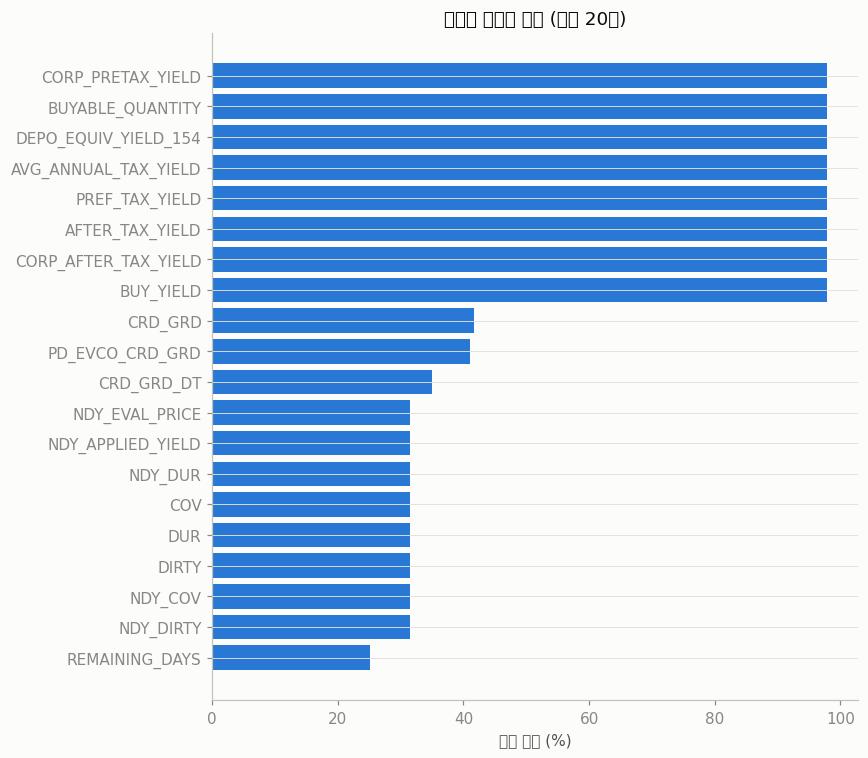

In [11]:
miss_top = missing[missing["missing_count"] > 0].head(20)
if len(miss_top):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(miss_top))))
    ax.barh(miss_top.index[::-1], miss_top["missing_pct"][::-1], color=CAT_COLORS[0])
    ax.set_xlabel("결측 비율 (%)")
    ax.set_title("컬럼별 결측치 비율 (상위 20개)")
    plt.tight_layout()
    plt.show()
else:
    print("결측치가 있는 컬럼이 없습니다.")


## 6. 중복 및 기본키(PD_NO) 무결성 체크

In [12]:
n_dup_rows = df.duplicated().sum()
print(f"완전 중복 행 수: {n_dup_rows:,}")

if "PD_NO" in df.columns:
    n_dup_pk = df["PD_NO"].duplicated().sum()
    print(f"PD_NO 중복 건수: {n_dup_pk:,} / 전체 {len(df):,}건")
    if n_dup_pk:
        display(df[df["PD_NO"].duplicated(keep=False)].sort_values("PD_NO").head(20))


완전 중복 행 수: 0
PD_NO 중복 건수: 0 / 전체 42,394건


## 7. 날짜형 컬럼 변환

스키마상 날짜 컬럼(`ISU_DT`, `MAT_DT`, `PD_STD_INFO_UPDATE`, `CRD_GRD_DT`)이 `double precision`으로 정의되어 있습니다.
실제 원본에서 흔히 나타나는 두 가지 형태(① `20210510` 같은 YYYYMMDD 정수, ② 엑셀 시리얼 넘버)를 모두 처리할 수 있는 헬퍼를 사용합니다.
값을 눈으로 확인한 뒤 필요 없는 분기는 지워도 됩니다.

In [13]:
def to_datetime_flexible(s: pd.Series) -> pd.Series:
    '''YYYYMMDD 정수/문자열 또는 엑셀 시리얼 넘버를 datetime으로 변환.'''
    s_num = pd.to_numeric(s, errors="coerce")

    # 1) YYYYMMDD 형태로 보이는 값 (8자리, 대략 1990~2100년 범위)
    yyyymmdd_mask = s_num.between(19900101, 21001231)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    out.loc[yyyymmdd_mask] = pd.to_datetime(
        s_num.loc[yyyymmdd_mask].astype("Int64").astype(str), format="%Y%m%d", errors="coerce"
    )

    # 2) 나머지는 엑셀 시리얼 넘버로 간주 (1899-12-30 기준)
    remain_mask = ~yyyymmdd_mask & s_num.notna()
    out.loc[remain_mask] = pd.to_datetime(
        s_num.loc[remain_mask], unit="D", origin="1899-12-30", errors="coerce"
    )
    return out


for col in DATE_COLS:
    df[f"{col}_DT"] = to_datetime_flexible(df[col])

df[[f"{c}_DT" for c in DATE_COLS]].describe()


,ISU_DT_DT,MAT_DT_DT,PD_STD_INFO_UPDATE_DT,CRD_GRD_DT_DT
count,0,0,0,0
mean,NaT,NaT,NaT,NaT
min,NaT,NaT,NaT,NaT
25%,NaT,NaT,NaT,NaT
50%,NaT,NaT,NaT,NaT
75%,NaT,NaT,NaT,NaT
max,NaT,NaT,NaT,NaT


In [14]:
for col in DATE_COLS:
    parsed = df[f"{col}_DT"]
    n_fail = parsed.isna().sum() - df[col].isna().sum()
    print(f"{col}: 변환 실패(추정) {max(n_fail, 0):,}건 / 결측 {df[col].isna().sum():,}건, "
          f"범위 [{parsed.min()} ~ {parsed.max()}]")


ISU_DT: 변환 실패(추정) 42,055건 / 결측 339건, 범위 [NaT ~ NaT]
MAT_DT: 변환 실패(추정) 42,075건 / 결측 319건, 범위 [NaT ~ NaT]
PD_STD_INFO_UPDATE: 변환 실패(추정) 31,823건 / 결측 10,571건, 범위 [NaT ~ NaT]
CRD_GRD_DT: 변환 실패(추정) 27,563건 / 결측 14,831건, 범위 [NaT ~ NaT]


## 8. 파생 변수 생성

In [15]:
AS_OF_DATE = df["PD_STD_INFO_UPDATE_DT"].max() if "PD_STD_INFO_UPDATE_DT" in df.columns else pd.Timestamp.today().normalize()
print(f"기준일(AS_OF_DATE): {AS_OF_DATE.date()}")

if "ISU_DT_DT" in df.columns:
    df["ISU_YEAR"] = df["ISU_DT_DT"].dt.year
    df["YEARS_SINCE_ISSUE"] = (AS_OF_DATE - df["ISU_DT_DT"]).dt.days / 365.25

if "MAT_DT_DT" in df.columns:
    df["MAT_YEAR"] = df["MAT_DT_DT"].dt.year
    df["YEARS_TO_MATURITY"] = (df["MAT_DT_DT"] - AS_OF_DATE).dt.days / 365.25

# 잔존만기 버킷 (REMAINING_DAYS가 있으면 그것을, 없으면 파생 YEARS_TO_MATURITY 사용)
maturity_years = None
if "REMAINING_DAYS" in df.columns:
    maturity_years = df["REMAINING_DAYS"] / 365.25
elif "YEARS_TO_MATURITY" in df.columns:
    maturity_years = df["YEARS_TO_MATURITY"]

if maturity_years is not None:
    bins = [-np.inf, 1, 3, 5, 10, 20, np.inf]
    labels = ["<1Y", "1-3Y", "3-5Y", "5-10Y", "10-20Y", "20Y+"]
    df["MATURITY_BUCKET"] = pd.cut(maturity_years, bins=bins, labels=labels)

df[[c for c in ["ISU_YEAR", "MAT_YEAR", "YEARS_SINCE_ISSUE", "YEARS_TO_MATURITY", "MATURITY_BUCKET"] if c in df.columns]].head()


기준일(AS_OF_DATE): NaT


,ISU_YEAR,MAT_YEAR,YEARS_SINCE_ISSUE,YEARS_TO_MATURITY,MATURITY_BUCKET
0,NaN,NaN,NaN,NaN,<1Y
1,NaN,NaN,NaN,NaN,<1Y
2,NaN,NaN,NaN,NaN,<1Y
3,NaN,NaN,NaN,NaN,<1Y
4,NaN,NaN,NaN,NaN,<1Y


## 9. 범주형 변수 EDA

In [16]:
for col in CATEGORY_COLS:
    vc = df[col].value_counts(dropna=False)
    print(f"\n### {col} (고유값 {df[col].nunique(dropna=False)}개)")
    display(vc.head(10).to_frame("count").assign(pct=lambda x: (x["count"] / len(df) * 100).round(2)))



### PD_EXG_MKT (고유값 2개)


,count,pct
PD_EXG_MKT,,
장내,24749,58.3800
장외,17645,41.6200



### PD_CTRY_CD (고유값 2개)


,count,pct
PD_CTRY_CD,,
KR,42393,100.0000
XS,1,0.0000



### PD_PBCM (고유값 8019개)


,count,pct
PD_PBCM,,
한국주택금융공사,2384,5.6200
한국산업은행,1076,2.5400
NaN,918,2.1700
(주)중소기업은행,720,1.7000
하나캐피탈(주),541,1.2800
대한민국,535,1.2600
한국토지주택공사,534,1.2600
현대캐피탈(주),514,1.2100
한국전력공사(주),511,1.2100


... (10 outputs left out)


### PD_RISK_GCD (고유값 7개)


,count,pct
PD_RISK_GCD,,
1,15950,37.6200
5,13696,32.3100
6,10408,24.5500
4,1938,4.5700
3,282,0.6700
2,62,0.1500
0,58,0.1400



### CRD_GRD (고유값 21개)


,count,pct
CRD_GRD,,
NaN,17644,41.6200
AAA,12240,28.8700
AA-,4939,11.6500
AA+,3191,7.5300
AA0,1713,4.0400
A+,906,2.1400
A0,904,2.1300
A-,345,0.8100
BBB+,206,0.4900


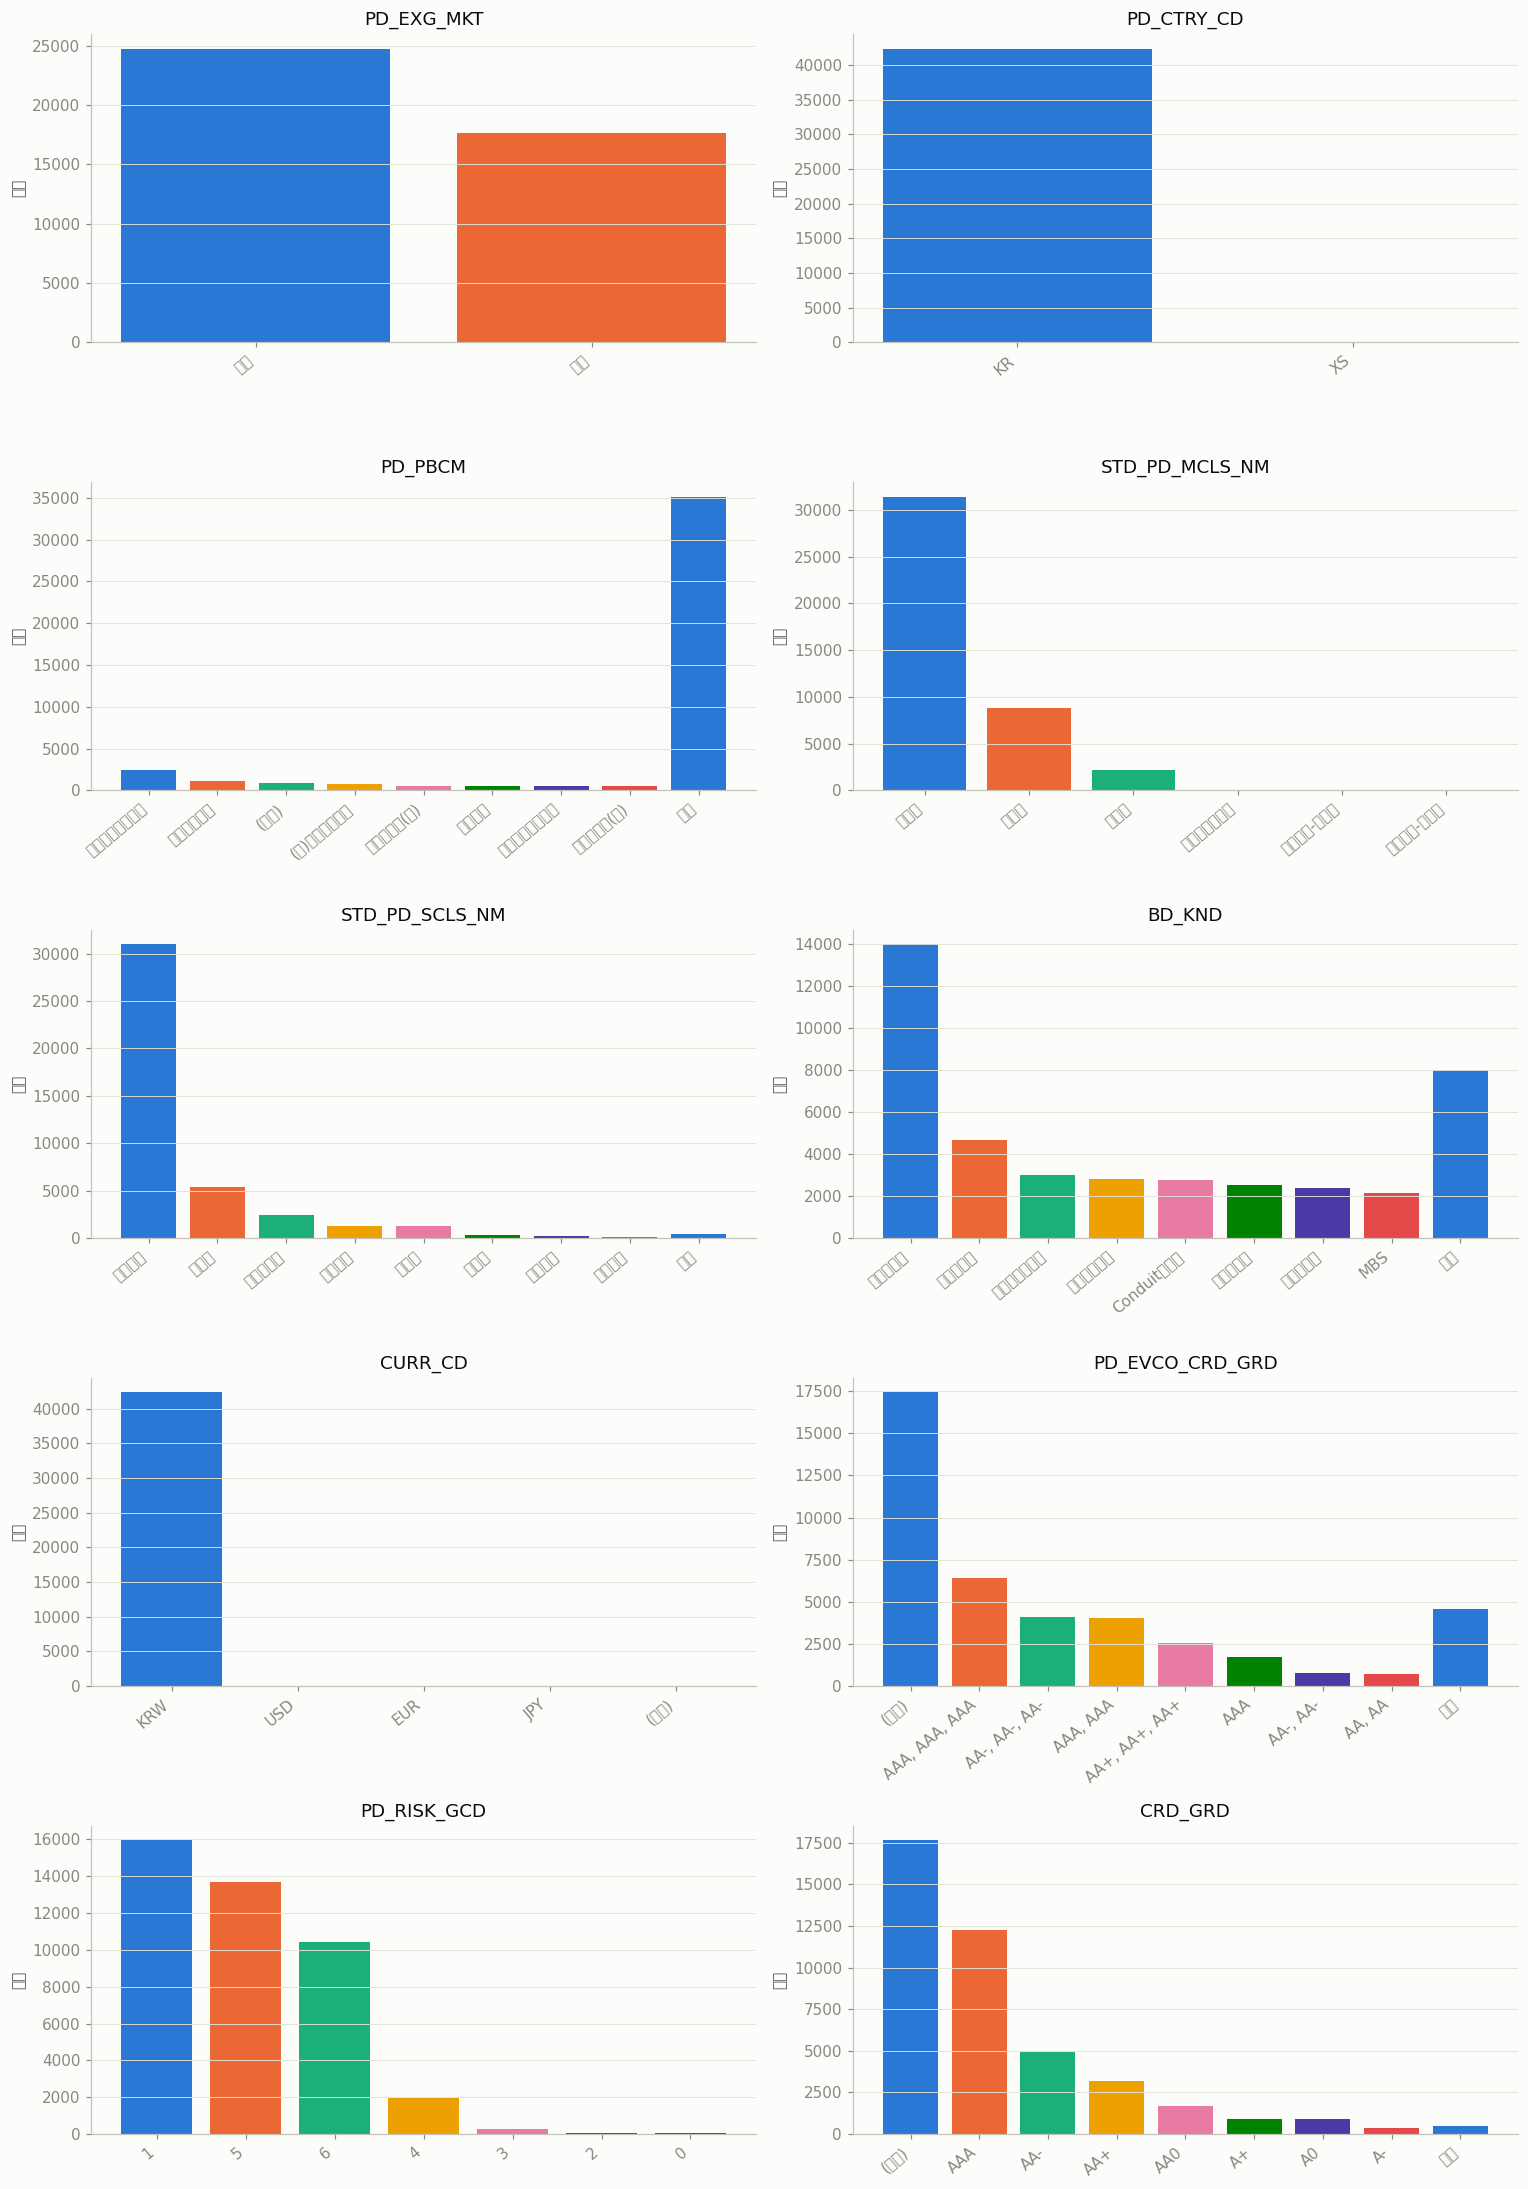

In [17]:
def plot_top_categories(col, top_n=8, ax=None):
    # NaN을 "(결측)" 문자열로 명시적으로 바꿔준 뒤 집계 (혼합 타입 인덱스로 인한 플로팅 오류 방지)
    vc = df[col].fillna("(결측)").astype(str).value_counts()
    top = vc.head(top_n)
    if len(vc) > top_n:
        other = pd.Series({"기타": vc.iloc[top_n:].sum()})
        top = pd.concat([top, other])

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(7, 4))
    colors = cat_colors(len(top))
    ax.bar([str(x) for x in top.index], top.values, color=colors)
    ax.set_title(col)
    ax.set_ylabel("건수")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    if own_ax:
        plt.tight_layout()
        plt.show()


n_cols = 2
n_rows = int(np.ceil(len(CATEGORY_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, CATEGORY_COLS):
    plot_top_categories(col, ax=ax)
for ax in axes[len(CATEGORY_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. 수치형 변수 기술통계

In [18]:
stats = df[NUMERIC_COLS].describe().T
stats["skew"] = df[NUMERIC_COLS].skew()
stats["kurtosis"] = df[NUMERIC_COLS].kurtosis()
stats.sort_values("skew", ascending=False)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
EVAL_PRICE,"31,823.0000","10,136.3496","4,905.5146",0.0000,"9,970.8300","10,029.9200","10,103.2500","414,569.5483",47.3122,"2,904.9323"
APPLIED_YIELD,"31,823.0000",3.8956,13.5638,-0.4150,2.8320,3.2270,3.6680,787.3270,32.9103,"1,295.9084"
NDY_APPLIED_YIELD,"29,018.0000",2.9968,14.1662,-0.2950,0.0000,3.0620,3.5200,787.3270,31.5600,"1,195.9361"
ISU_BAL_AMT,"42,394.0000","89,366,774,285.1626","733,778,868,585.7551",0.0000,"970,000,000.0000","12,442,915,000.0000","70,000,000,000.0000","46,971,000,000,000.0000",30.0197,"1,211.4385"
DIRTY,"29,018.0000","10,051.7426","1,749.0798",0.0000,"9,958.1000","10,038.5500","10,109.9575","77,323.0800",15.4181,448.7497
COV,"29,018.0000",19.3818,89.6940,0.0000,0.0000,1.1528,6.4546,"2,499.0000",12.1005,215.0405
NDY_COV,"29,018.0000",19.4543,90.4822,0.0000,0.0000,1.0612,6.4277,"2,499.0000",11.9478,208.9134
BUYABLE_QUANTITY,881.0000,"182,934,338.2520","1,099,723,795.4253",0.0000,0.0000,0.0000,"4,861,000.0000","12,323,631,000.0000",7.5026,59.4028
NDY_DUR,"29,018.0000",2.0065,3.7367,0.0000,0.0000,0.8948,2.3811,99.0000,5.5136,61.5940
DUR,"29,018.0000",2.0184,3.7075,0.0000,0.0000,0.9150,2.4004,99.0000,5.5063,62.4825


## 11. 수치형 변수 분포 시각화

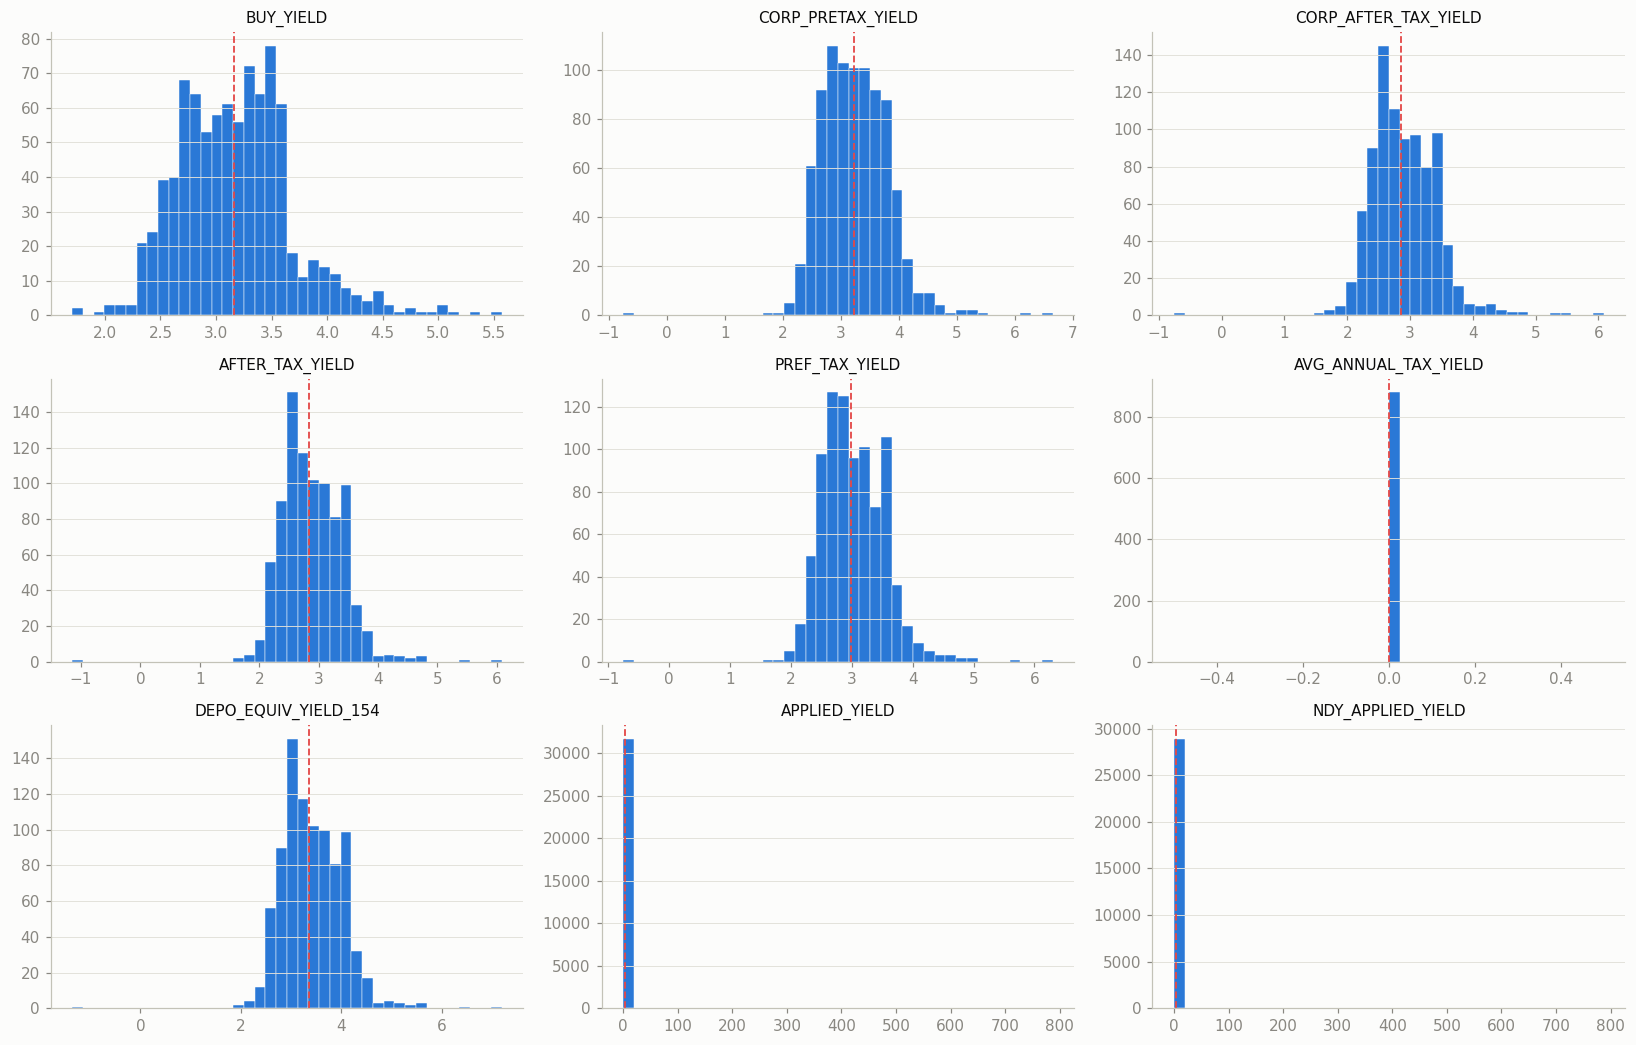

In [19]:
def plot_histograms(cols, n_cols=3, bins=40):
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cols):
        data = df[col].dropna()
        ax.hist(data, bins=bins, color=CAT_COLORS[0], edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
        ax.axvline(data.median(), color=CAT_COLORS[7], linewidth=1.2, linestyle="--", label="median")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_histograms(YIELD_COLS)


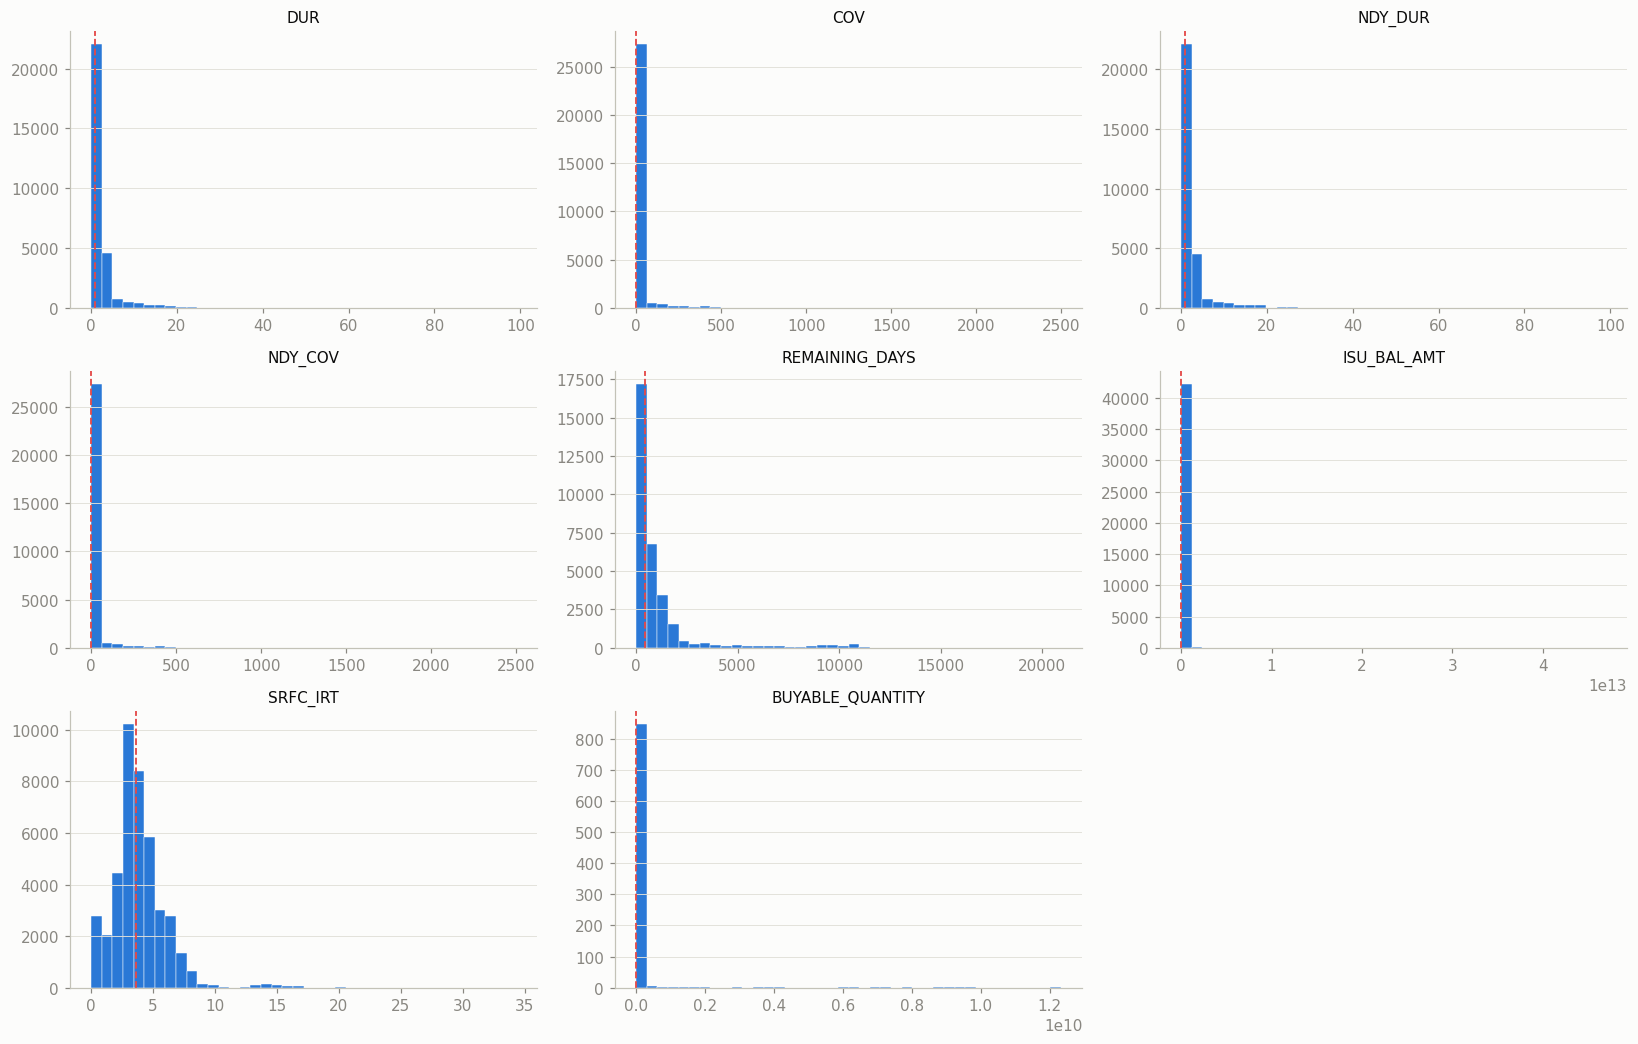

In [20]:
plot_histograms(RISK_COLS + OTHER_NUMERIC_COLS)


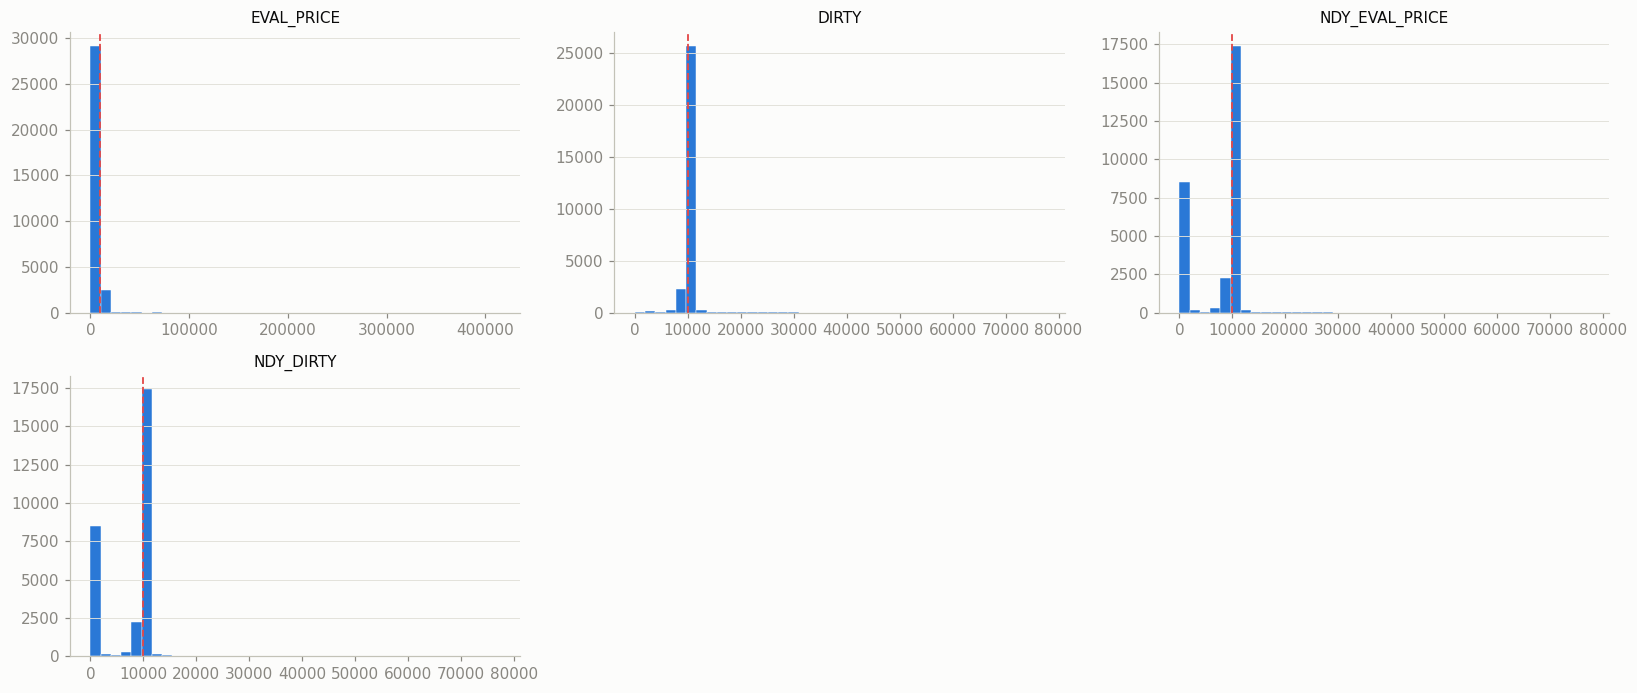

In [21]:
plot_histograms(PRICE_COLS)


## 12. 이상치 탐지 (IQR 기준)

In [22]:
def iqr_outlier_summary(cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({
            "column": col, "q1": q1, "q3": q3, "iqr": iqr,
            "lower": lo, "upper": hi,
            "n_outliers": n_out, "pct_outliers": round(n_out / len(s) * 100, 2),
        })
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)


outlier_summary = iqr_outlier_summary(NUMERIC_COLS)
outlier_summary


,column,q1,q3,iqr,lower,upper,n_outliers,pct_outliers
9,EVAL_PRICE,"9,970.8300","10,103.2500",132.4200,"9,772.2000","10,301.8800",6788,21.3300
20,BUYABLE_QUANTITY,0.0000,"4,861,000.0000","4,861,000.0000","-7,291,500.0000","12,152,500.0000",185,21.0000
10,DIRTY,"9,958.1000","10,109.9575",151.8575,"9,730.3138","10,337.7438",5876,20.2500
16,NDY_COV,0.0000,6.4277,6.4277,-9.6416,16.0693,3958,13.6400
14,COV,0.0000,6.4546,6.4546,-9.6818,16.1364,3945,13.6000
7,APPLIED_YIELD,2.8320,3.6680,0.8360,1.5780,4.9220,4177,13.1300
18,ISU_BAL_AMT,"970,000,000.0000","70,000,000,000.0000","69,030,000,000.0000","-102,575,000,000.0000","173,545,000,000.0000",3681,8.6800
17,REMAINING_DAYS,4.0000,"1,030.0000","1,026.0000","-1,535.0000","2,569.0000",2493,7.8500
15,NDY_DUR,0.0000,2.3811,2.3811,-3.5716,5.9527,2009,6.9200
13,DUR,0.0000,2.4004,2.4004,-3.6006,6.0009,1985,6.8400


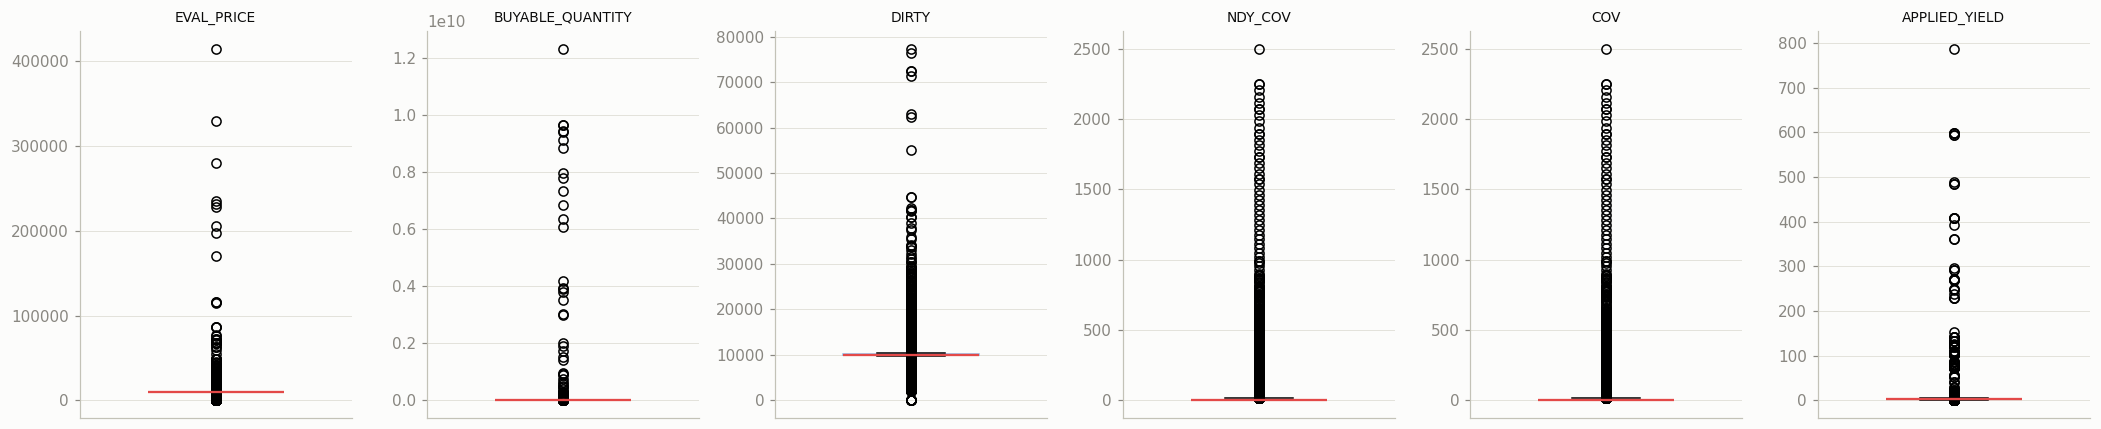

In [23]:
top_outlier_cols = outlier_summary.head(6)["column"].tolist()
if top_outlier_cols:
    fig, axes = plt.subplots(1, len(top_outlier_cols), figsize=(3.2 * len(top_outlier_cols), 4))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, top_outlier_cols):
        bp = ax.boxplot(df[col].dropna(), patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title(col, fontsize=9)
        ax.set_xticks([])
    plt.tight_layout()
    plt.show()


## 13. 발행잔액(ISU_BAL_AMT) 분석

,PD_NO,PD_NM,STD_PD_MCLS_NM,BD_KND,ISU_BAL_AMT
244,KR103502GB33,국고채권 01875-5103(21-2),국공채,국고채권,46971000000000
240,KR103502GA34,국고채권 01500-5003(20-2),국공채,국고채권,40113000000000
260,KR103502GF39,국고채권 02625-5503(25-2),국공채,국고채권,38404000000000
210,KR103501GF63,국고채권 02250-2806(25-4),국공채,국고채권,28603000000000
256,KR103502GE30,국고채권 03250-5403(24-2),국공채,국고채권,28369050000000
251,KR103502GD31,국고채권 03250-5303(23-2),국공채,국고채권,26250205000000
247,KR103502GC32,국고채권 02500-5203(22-2),국공채,국고채권,26140010100000
262,KR103502GF96,국고채권 02625-5509(25-7),국공채,국고채권,24963000000000
241,KR103502GA67,국고채권 01375-3006(20-4),국공채,국고채권,22967000000000
235,KR103502G933,국고채권 02000-4903(19-2),국공채,국고채권,20807614000000


,count,sum,mean
STD_PD_MCLS_NM,,,
국공채,2137,1548731907799000,"724,722,465,043.9869"
특수채,8755,1183350048925100,"135,162,769,723.0268"
회사채,31447,1054371600421084,"33,528,527,376.8908"
개인투자용국채,49,2161341900000,"44,109,018,367.3469"
외화채권-금융채,1,130000000,"130,000,000.0000"
외화채권-회사채,5,0,0.0000


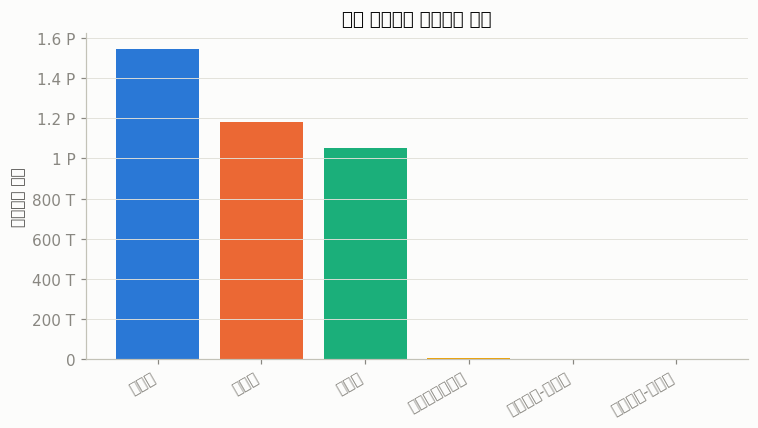

In [24]:
if "ISU_BAL_AMT" in df.columns:
    top_issuers = df.nlargest(20, "ISU_BAL_AMT")[["PD_NO", "PD_NM", "STD_PD_MCLS_NM", "BD_KND", "ISU_BAL_AMT"]]
    display(top_issuers)

    if "STD_PD_MCLS_NM" in df.columns:
        by_class = (
            df.groupby("STD_PD_MCLS_NM")["ISU_BAL_AMT"]
            .agg(["count", "sum", "mean"])
            .sort_values("sum", ascending=False)
        )
        display(by_class)

        fig, ax = plt.subplots(figsize=(7, 4))
        colors = cat_colors(len(by_class))
        ax.bar([str(x) for x in by_class.index], by_class["sum"], color=colors)
        ax.set_title("상품 대분류별 발행잔액 합계")
        ax.set_ylabel("발행잔액 합계")
        ax.tick_params(axis="x", rotation=30)
        for label in ax.get_xticklabels():
            label.set_ha("right")
        ax.yaxis.set_major_formatter(mticker.EngFormatter())
        plt.tight_layout()
        plt.show()


## 14. 만기 구조 분석

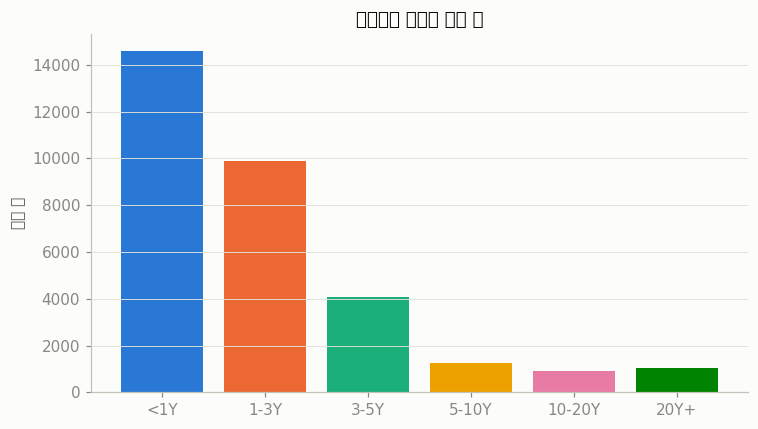

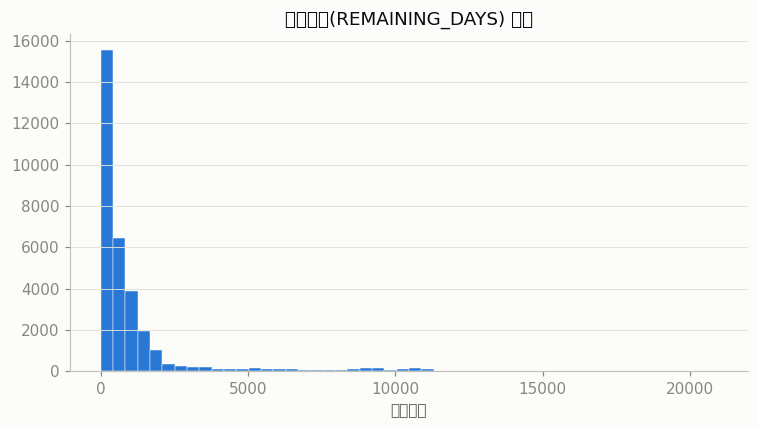

In [25]:
if "MATURITY_BUCKET" in df.columns:
    bucket_counts = df["MATURITY_BUCKET"].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar([str(x) for x in bucket_counts.index], bucket_counts.values, color=cat_colors(len(bucket_counts)))
    ax.set_title("잔존만기 구간별 종목 수")
    ax.set_ylabel("종목 수")
    plt.tight_layout()
    plt.show()

if "REMAINING_DAYS" in df.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(df["REMAINING_DAYS"].dropna(), bins=50, color=CAT_COLORS[0], edgecolor="white", linewidth=0.3)
    ax.set_title("잔존일수(REMAINING_DAYS) 분포")
    ax.set_xlabel("잔존일수")
    plt.tight_layout()
    plt.show()


## 15. 신용등급(CRD_GRD) 분석

,count
CRD_GRD,
(결측),17644
AAA,12240
AA-,4939
AA+,3191
AA0,1713
A+,906
A0,904
A-,345
BBB+,206


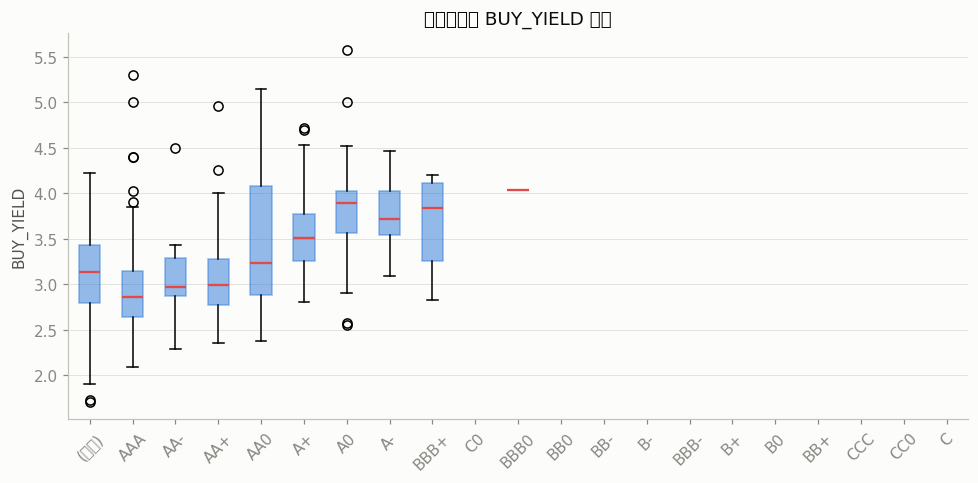

In [26]:
if "CRD_GRD" in df.columns:
    crd_grd_filled = df["CRD_GRD"].fillna("(결측)").astype(str)
    grade_counts = crd_grd_filled.value_counts()
    display(grade_counts.to_frame("count"))

    if "BUY_YIELD" in df.columns:
        order = grade_counts.index.tolist()
        fig, ax = plt.subplots(figsize=(9, 4.5))
        data_by_grade = [df.loc[crd_grd_filled == g, "BUY_YIELD"].dropna() for g in order]
        bp = ax.boxplot(data_by_grade, labels=[str(g) for g in order], patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title("신용등급별 BUY_YIELD 분포")
        ax.set_ylabel("BUY_YIELD")
        ax.tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()


## 16. 수익률(Yield) 컬럼 간 비교

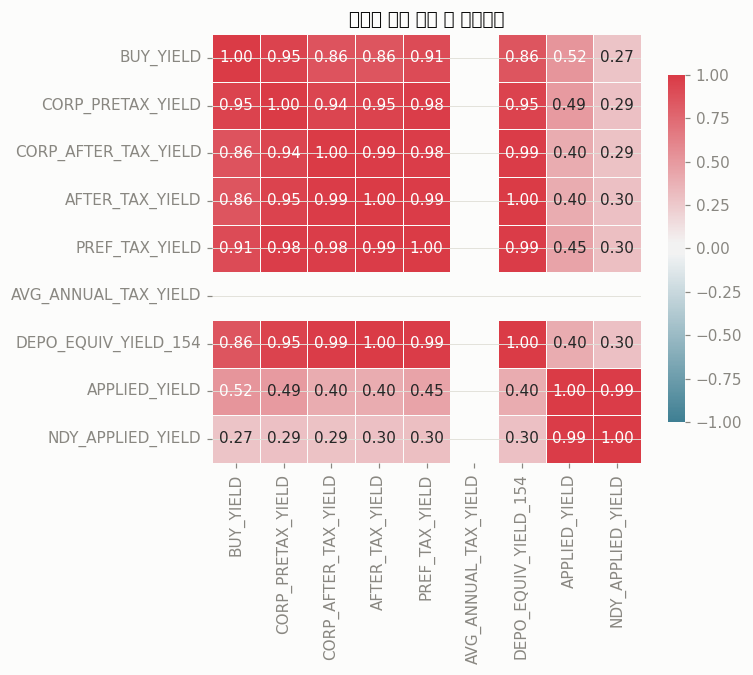

In [27]:
yield_corr = df[YIELD_COLS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    yield_corr, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor=SURFACE,
    cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("수익률 관련 컬럼 간 상관관계")
plt.tight_layout()
plt.show()


## 17. 듀레이션(DUR) vs 수익률(BUY_YIELD) 산점도

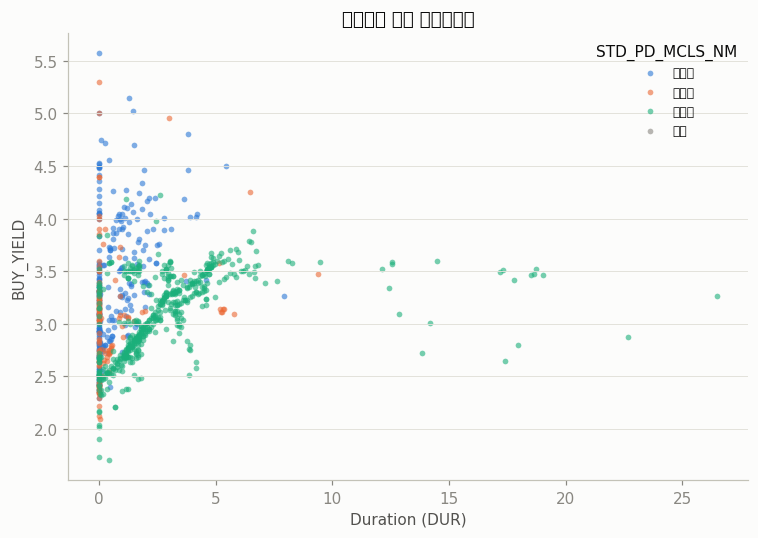

In [28]:
if {"DUR", "BUY_YIELD"}.issubset(df.columns):
    hue_col = "STD_PD_MCLS_NM" if "STD_PD_MCLS_NM" in df.columns else None

    fig, ax = plt.subplots(figsize=(7, 5))
    if hue_col:
        # 팔레트 규칙: scatter처럼 모든 쌍이 동시에 보이는 차트는 상위 3개 카테고리까지만
        # 검증된 색으로 표시하고 나머지는 '기타'로 묶습니다.
        top_cats = df[hue_col].value_counts().head(3).index.tolist()
        plot_df = df.copy()
        plot_df[hue_col] = plot_df[hue_col].where(plot_df[hue_col].isin(top_cats), "기타")
        cats = top_cats + (["기타"] if plot_df[hue_col].eq("기타").any() else [])
        colors = CAT_COLORS[:len(top_cats)] + ([INK_MUTED] if "기타" in cats else [])
        for cat, color in zip(cats, colors):
            sub = plot_df[plot_df[hue_col] == cat]
            ax.scatter(sub["DUR"], sub["BUY_YIELD"], s=14, alpha=0.6, color=color, label=str(cat), linewidths=0)
        ax.legend(title=hue_col, frameon=False, fontsize=8)
    else:
        ax.scatter(df["DUR"], df["BUY_YIELD"], s=14, alpha=0.5, color=CAT_COLORS[0], linewidths=0)

    ax.set_xlabel("Duration (DUR)")
    ax.set_ylabel("BUY_YIELD")
    ax.set_title("듀레이션 대비 매입수익률")
    plt.tight_layout()
    plt.show()


## 18. 수치형 변수 전체 상관관계

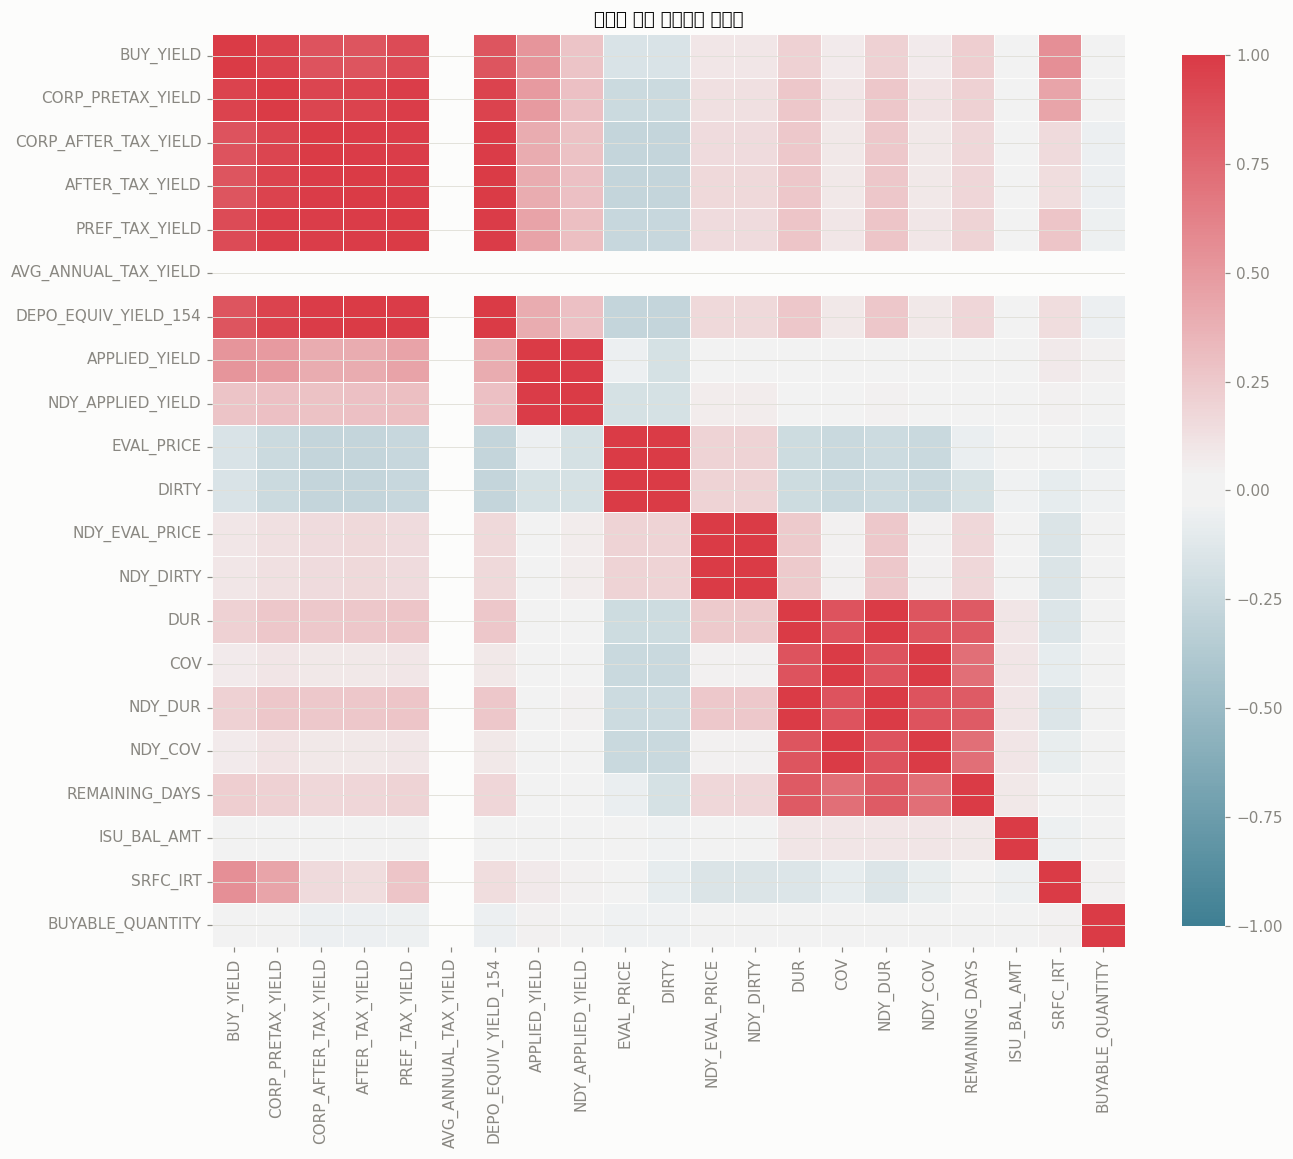

In [29]:
corr = df[NUMERIC_COLS].corr()
fig, ax = plt.subplots(figsize=(0.5 * len(NUMERIC_COLS) + 2, 0.5 * len(NUMERIC_COLS) + 2))
sns.heatmap(
    corr, cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.4, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax,
)
ax.set_title("수치형 변수 상관관계 히트맵")
plt.tight_layout()
plt.show()


In [30]:
# 상관관계 절대값 기준 상위 페어 (자기 자신 제외)
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .to_frame()
    .assign(abs_corr=lambda x: x["corr"].abs())
    .sort_values("abs_corr", ascending=False)
)
corr_pairs.head(20)


corr  abs_corr
AFTER_TAX_YIELD      DEPO_EQUIV_YIELD_154 1.0000    1.0000
NDY_EVAL_PRICE       NDY_DIRTY            1.0000    1.0000
COV                  NDY_COV              0.9963    0.9963
EVAL_PRICE           DIRTY                0.9958    0.9958
DUR                  NDY_DUR              0.9943    0.9943
PREF_TAX_YIELD       DEPO_EQUIV_YIELD_154 0.9906    0.9906
AFTER_TAX_YIELD      PREF_TAX_YIELD       0.9906    0.9906
CORP_AFTER_TAX_YIELD DEPO_EQUIV_YIELD_154 0.9890    0.9890
                     AFTER_TAX_YIELD      0.9890    0.9890
APPLIED_YIELD        NDY_APPLIED_YIELD    0.9872    0.9872
CORP_AFTER_TAX_YIELD PREF_TAX_YIELD       0.9827    0.9827
CORP_PRETAX_YIELD    PREF_TAX_YIELD       0.9818    0.9818
                     DEPO_EQUIV_YIELD_154 0.9479    0.9479
                     AFTER_TAX_YIELD      0.9479    0.9479
BUY_YIELD            CORP_PRETAX_YIELD    0.9471    0.9471
CORP_PRETAX_YIELD    CORP_AFTER_TAX_YIELD 0.9411    0.9411
BUY_YIELD            PREF_TAX_YIELD       0.9098    0.9098
NDY_DUR              NDY_COV              0.8638    0.8638
BUY_YIELD            CORP_AFTER_TAX_YIELD 0.8616    0.8616
COV                  NDY_DUR              0.8610    0.8610

## 19. 채권종류(BD_KND)별 요약

In [33]:
if "BD_KND" in df.columns:
    agg_dict = {"PD_NO": "count"}
    for c in ["SRFC_IRT", "BUY_YIELD", "REMAINING_DAYS", "DUR", "ISU_BAL_AMT"]:
        if c in df.columns:
            agg_dict[c] = "mean" if c != "ISU_BAL_AMT" else "sum"

    summary_by_kind = df.groupby("BD_KND").agg(agg_dict).rename(columns={"PD_NO": "종목수"})
    summary_by_kind.sort_values("종목수", ascending=False)
